# 03. Self-consistency in the original code

Translate the original pairing and density iteration, one step at a time. Record residuals so that a fixed iteration count is not mistaken for convergence.

**Read this notebook from top to bottom.** Each section explains one calculation before showing its code. All functions needed to run it are visible below; no earlier notebook is required.

**Source labels.** **Thesis** identifies the stated model in Aditya Banerjee's [2023 MSc thesis](https://drive.google.com/file/d/1d9WheYwEY23cPAlLxxVOUfQDr9jLdqb9/view). **Source translation** identifies the active Mathematica calculation at commit `d88d12c`. **Extension / algebra** identifies new Python implementation or explicit derivations. Numerical output is evidence only for the displayed parameters. No speculative physical identification is assumed.

**Units and conventions.** Choose one energy unit $E_0$ and lattice spacing $a$. Displayed energies mean $E/E_0$, coordinates mean $x/a$, and $k_x,k_y$ mean momentum times $a$. Thus $m,\lambda,\mu,\Delta,V,k_BT$ all have energy units before rescaling. Eigenvectors have norm one and dimensionless components. This is a nonrelativistic lattice calculation; no spacetime metric signature is used. Boundary conditions and the spin/Nambu basis are stated where each matrix is built.

**Code provenance.** The original files are [BdG topological.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/BdG%20topological.nb) and [added vortex.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/added%20vortex.nb). See [SOURCE_MAP.md](../SOURCE_MAP.md) for exact cells, differences and references. Python functions are also collected in `python/bdg_models.py` for testing; the definitions here are identical.

## 1. Imports

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import expit
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

## 2. Occupation numbers and source conventions

**Thesis:** §4.1, pp. 30–33, describes iterating the BdG spectrum and mean fields. **Source translation:** the equations below are the actual sums in input cell 5, expressed in the signed-hole basis explained in notebook 02. They are not a claim that every thesis mean-field formula has the same normalization.

Write each normalized eigenvector as $(u_{i\uparrow,n},u_{i\downarrow,n},v_{i\uparrow,n},v_{i\downarrow,n})$ across all sites $i$ and states $n$. The Fermi function is
$$f(E)=\frac{1}{e^{E/(k_BT)}+1}.$$
$k_BT$ is a thermal **energy**, not temperature alone. The source sets $k_BT=0.001$ and replaces $f$ by exactly $0$ above $0.02$ and $1$ below $-0.02$, in its chosen energy unit. We keep that cutoff. It differs slightly from the smooth Fermi function. As $T\to0$, $f(E<0)\to1$, $f(E>0)\to0$, and $f(0)=1/2$.

Every sum below is over **all $4N$ states**:
$$n_{i\uparrow}=\sum_n|u_{i\uparrow,n}|^2 f(E_n),\quad
n_{i\downarrow}=\sum_n|v_{i\downarrow,n}|^2[1-f(E_n)],$$
$$n_i=n_{i\uparrow}+n_{i\downarrow},\qquad m_i=n_{i\uparrow}-n_{i\downarrow},$$
$$s_i^{\rm proposed}=v_s\sum_n\left(u_{i\uparrow,n}v_{i\downarrow,n}^*
+u_{i\downarrow,n}v_{i\uparrow,n}^*\right)f(E_n).$$
Here $n_i$ is electrons per site ($0\le n_i\le2$), $m_i$ is a dimensionless spin-population difference (not a magnetic moment in SI units), and $v_s$ is the source pairing coupling. Eigenvector products and $f$ are dimensionless, so $s_i$ has the same energy units as $v_s$. Do not add a positive-spectrum factor of two to these full-spectrum formulas.

In [2]:
def coordinates(nx, ny):
    """Zero-based version of the source's x-outer, y-inner site order."""
    return np.array([(x, y) for x in range(nx) for y in range(ny)])

def legacy_blocks(nx, ny, m=0.5, lam=1.0):
    """Translate first Code cell: periodic dictionary hopping, not thesis Eq. 4.9.

    Require >=3 sites per direction so nearest-neighbour images are distinct.
    The source selects the first numeric periodic image, rather than summing
    duplicate images. These coincide for the supported sizes.
    """
    if min(nx, ny) < 3:
        raise ValueError('Legacy translation requires nx, ny >= 3.')
    xy = coordinates(nx, ny)
    n = nx * ny
    hopping = {(0, 0): 1.5*m}
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        hopping[dx, dy] = -m
    for dx in [-1, 1]:
        for dy in [-1, 1]:
            hopping[dx, dy] = m/4
    mixing = {d: lam*(1-1j) for d in [(1, 0), (-1, 0), (0, 1), (0, -1)]}

    def from_dictionary(entries):
        matrix = np.zeros((n, n), complex)
        for i, (x, y) in enumerate(xy):
            for (dx, dy), value in entries.items():
                j = ((x-dx) % nx)*ny + (y-dy) % ny
                matrix[i, j] = value
        return matrix.T  # source: tij[i][j] = tijmn[[j,i]]

    return from_dictionary(hopping), from_dictionary(mixing)

def legacy_bdg(h1, soc, mu, st):
    """Translate active hh1, hh2, SCs and H of Mathematica input cell 5."""
    n = len(st)
    diagonal = h1 + mu*np.eye(n)
    electron = np.block([[diagonal, soc], [soc.conj(), diagonal]])
    hole = np.block([[-diagonal.conj(), soc.conj()],
                     [soc, -diagonal.conj()]])
    zero = np.zeros((n, n), complex)
    pairing = np.block([[zero, np.diag(st)], [np.diag(st), zero]])
    return np.block([[electron, pairing], [pairing.conj(), hole]])

def source_fermi(energies, kT=0.001):
    """Original cutoff at +/-0.02, with a stable exponential evaluation."""
    return np.where(energies > 0.02, 0.0,
                    np.where(energies < -0.02, 1.0, expit(-energies/kT)))

def source_observables(energies, vectors, vs):
    """Original full-spectrum sums; numpy eigenvectors are COLUMNS."""
    n = vectors.shape[0]//4
    up, down, hole_up, hole_down = np.split(vectors, 4, axis=0)
    f = source_fermi(energies)
    n_up = abs(up)**2 @ f
    n_down = abs(hole_down)**2 @ (1-f)
    st_new = vs*((up*hole_down.conj() + down*hole_up.conj()) @ f)
    return n_up+n_down, n_up-n_down, st_new

## 3. Update the pairing and chemical potential

**Source translation:** initialize $s_i=-0.01$, $\mu=0$. At each iteration, compute the mean density $\bar n=N^{-1}\sum_i n_i$ and apply
$$\mu_{\rm new}=\mu-\alpha(n_{\rm target}-\bar n),\qquad \alpha=0.1E_0,$$
$$s_{i,\rm new}=\tfrac12s_i^{\rm proposed}+\tfrac12s_i.$$
The factor $1/2$ mixes old and proposed gaps. In the source electron block the chemical potential enters as **$+\mu$**. If the density is too small, $n_{\rm target}-\bar n>0$, so the update lowers $\mu$, lowers electron energies and favours filling. The thesis convention $-\mu$ would require a separate sign analysis.

**Added diagnostic:** $r_s=\max_i|s_i^{\rm proposed}-s_i|$ has energy units and $r_n=|\bar n-n_{\rm target}|$ is dimensionless. We report them independently. Small $r_s$ alone is insufficient. The original loop performs exactly 100 iterations, with no convergence test; this notebook preserves that behavior and adds residual reporting, including a fresh evaluation after the last update.

In [3]:
def source_iteration(nx=4, ny=4, vs=-1.45, target=1.2, steps=100):
    """Original fixed-count iteration; residual logging is added for diagnosis."""
    h1, soc = legacy_blocks(nx, ny)
    st = np.full(nx*ny, -0.01, complex)
    mu = 0.0
    history = []
    for iteration in range(steps):
        energies, vectors = eigh(legacy_bdg(h1, soc, mu, st))
        density, magnetization, proposed = source_observables(energies, vectors, vs)
        mean_density = density.mean()
        history.append([iteration+1, mu, mean_density, abs(st).mean(),
                        np.max(abs(proposed-st)), abs(mean_density-target),
                        abs(magnetization).mean()])
        mu = mu - 0.1*(target-mean_density)
        st = 0.5*proposed + 0.5*st
    # Extra diagnostic evaluation of the returned, UPDATED fields.
    energies, vectors = eigh(legacy_bdg(h1, soc, mu, st))
    density, magnetization, proposed = source_observables(energies, vectors, vs)
    residuals = np.array([np.max(abs(proposed-st)), abs(density.mean()-target)])
    return mu, st, np.array(history), residuals

In [4]:
# Small periodic lattice for a quick, fully executed tutorial.
# Original source uses nx=ny=20 (1600 x 1600 BdG matrix).
nx = ny = 4
cases = {"BdG topological.nb": (-1.45, 1.2),
         "added vortex.nb": (-1.25, 1.0)}
runs = {}
for label, (vs, target) in cases.items():
    mu, st, history, residuals = source_iteration(nx, ny, vs, target, steps=100)
    runs[label] = (mu, st, history, residuals)
    converged = residuals[0] < 1e-6 and residuals[1] < 1e-6
    print(label)
    print(f"  mu/E0={mu:.6f}; mean |st|/E0={abs(st).mean():.6g}")
    print(f"  final gap residual/E0={residuals[0]:.3e}; density residual={residuals[1]:.3e}")
    print("  Meets both displayed 1e-6 tolerances:", converged)

BdG topological.nb
  mu/E0=-0.926143; mean |st|/E0=0.433849
  final gap residual/E0=9.333e-05; density residual=7.505e-04
  Meets both displayed 1e-6 tolerances: False


added vortex.nb
  mu/E0=-0.606281; mean |st|/E0=0.413549
  final gap residual/E0=1.141e-05; density residual=4.791e-04
  Meets both displayed 1e-6 tolerances: False


## 4. Inspect convergence rather than assume it

The curves below record fields **before each update**. The printed residuals above are recomputed for the final returned fields. A plateau or small gap does not by itself establish convergence or superconductivity. Changing lattice size changes the finite spectrum and can change the iteration behavior.

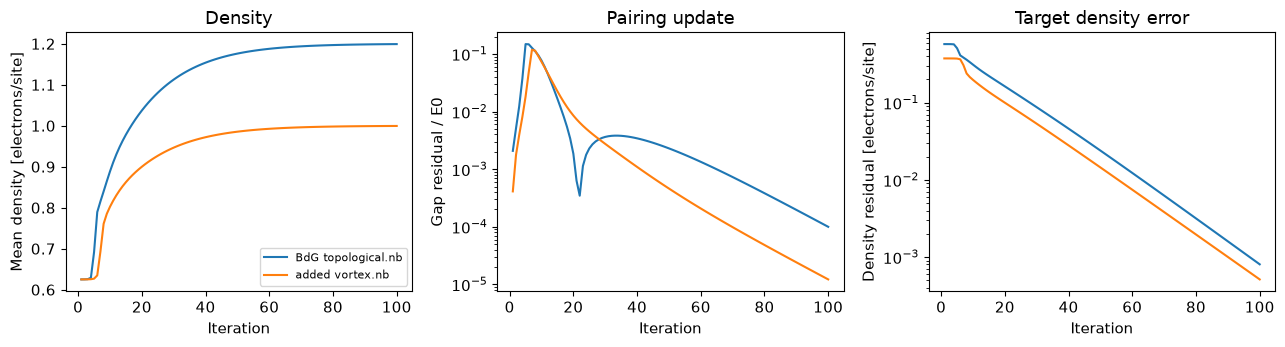

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for label, (_, _, history, _) in runs.items():
    axes[0].plot(history[:, 0], history[:, 2], label=label)
    axes[1].semilogy(history[:, 0], np.maximum(history[:, 4], 1e-16), label=label)
    axes[2].semilogy(history[:, 0], np.maximum(history[:, 5], 1e-16), label=label)
axes[0].set(ylabel="Mean density [electrons/site]", title="Density")
axes[1].set(ylabel="Gap residual / E0", title="Pairing update")
axes[2].set(ylabel="Density residual [electrons/site]", title="Target density error")
for ax in axes:
    ax.set_xlabel("Iteration")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Scope of this result

**Verified calculation:** this is a Python translation of the active periodic, spatially uniform initialization and update rules. Dense Hermitian diagonalization replaces Mathematica `Eigensystem`; the saved Mathematica outputs have not been independently reproduced with Wolfram. The prototype vortex block is commented out in both source notebooks. Therefore these iterations do not create a vortex. The next notebook introduces a separately labelled imposed vortex field from the thesis; it is not the converged output of this notebook.